In [1]:
import os
print('running from:', os.getcwd())
print('data folder found:', os.path.isdir('data'))
print('outputs folder found:', os.path.isdir('outputs'))

running from: /Users/ismayasmin/Documents/DWC26_project
data folder found: True
outputs folder found: True


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

DATA_DIR = 'data'
OUT_DIR = 'outputs'

print('notebook is running in:', os.getcwd())
print(os.listdir(OUT_DIR))
print(os.listdir(DATA_DIR))

notebook is running in: /Users/ismayasmin/Documents/DWC26_project
['oil_cumulative_quarterly.csv', 'forecast_rates.png', 'best10_given_cases.csv', 'model_comparison_oil.png', 'gas_cumulative_quarterly.csv', 'water_cumulative_quarterly.csv', 'model_comparison_all_fluids.png', 'quarterly_volumes_and_rates.csv', 'revenue_scenarios.csv', 'forecast_charts.png', 'assumptions.md', 'best10_settings.csv', 'pca_gpr_model.joblib', 'case_settings.csv', 'template_case_mapping.csv', 'scaling.npz', 'model_comparison_validation.csv', 'dense_model.keras', 'forecast_filled_template.xlsx']
['03_Train_Cases_1__Case_1.csv', '02 Field Production.xlsx', '07__Validation_Cases__Case_71.csv', '01 Introduction.xlsx', '09 Template Deliverable.xlsx']


## Step a: load and prepare data

In [3]:
settings = pd.read_csv(f'{OUT_DIR}/case_settings.csv')
oil   = pd.read_csv(f'{OUT_DIR}/oil_cumulative_quarterly.csv', index_col=0, parse_dates=True)
gas   = pd.read_csv(f'{OUT_DIR}/gas_cumulative_quarterly.csv', index_col=0, parse_dates=True)
water = pd.read_csv(f'{OUT_DIR}/water_cumulative_quarterly.csv', index_col=0, parse_dates=True)

print(settings.shape, oil.shape, gas.shape, water.shape)
print('blank cells:', int(oil.isna().sum().sum() + gas.isna().sum().sum() + water.isna().sum().sum()))
print(oil[['Case_1', 'Case_90', 'Observed']].tail(2))

(100, 5) (41, 101) (41, 101) (41, 101)
blank cells: 0
                Case_1     Case_90      Observed
2007-10-01  34720492.0  37833272.0  3.789561e+07
2008-01-01  35150436.0  38378920.0  3.837832e+07


In [4]:
SETTING_COLS = ['Fault Transmissibility', 'Porosity Multiplier',
                'Permeability Multiplier', 'Aquifer Pore Volume']
case_cols = [f'Case_{i}' for i in range(1, 101)]

X = settings[SETTING_COLS].values
Y = np.hstack([oil[case_cols].T.values, gas[case_cols].T.values, water[case_cols].T.values])

train_idx, val_idx, test_idx = np.arange(0, 70), np.arange(70, 85), np.arange(85, 100)

print(X.shape, Y.shape)
print(settings['Item'].iloc[[0, 69, 70, 84, 85, 99]].tolist())

(100, 4) (100, 123)
['Case 1', 'Case 70', 'Case 71', 'Case 85', 'Case 86', 'Case 100']


In [5]:
mu, sd = X[train_idx].mean(axis=0), X[train_idx].std(axis=0)
scale = np.concatenate([np.full(41, Y[train_idx][:, k*41:(k+1)*41].max()) for k in range(3)])

def scale_X(a):
    return (a - mu) / sd

Xtr, Xva = scale_X(X[train_idx]), scale_X(X[val_idx])
Ytr, Yva = Y[train_idx] / scale, Y[val_idx] / scale

print('settings, average:', Xtr.mean(axis=0).round(2), ' spread:', Xtr.std(axis=0).round(2))
print('curves, smallest and largest:', Ytr.min().round(3), Ytr.max().round(3))

settings, average: [-0. -0. -0.  0.]  spread: [1. 1. 1. 1.]
curves, smallest and largest: 0.0 1.0


## Step b: dense neural network (benchmark)

In [6]:
keras.utils.set_random_seed(42)

dense = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(123),
])
dense.compile(optimizer='adam', loss='mse')

stop = keras.callbacks.EarlyStopping(patience=50, restore_best_weights=True)
history = dense.fit(Xtr, Ytr, validation_data=(Xva, Yva),
                    epochs=1000, batch_size=8, callbacks=[stop], verbose=0)

print('trained for', len(history.history['loss']), 'rounds')

trained for 1000 rounds


## Step c: validation errors of the benchmark

In [7]:
pred = dense.predict(Xva, verbose=0) * scale
true = Y[val_idx]

for k, fluid in enumerate(['oil', 'gas', 'water']):
    t, p = true[:, k*41:(k+1)*41], pred[:, k*41:(k+1)*41]
    whole = np.abs(p - t).sum() / t.sum() * 100
    final = np.mean(np.abs(p[:, -1] - t[:, -1]) / t[:, -1]) * 100
    print(f'{fluid}: whole-curve error {whole:.2f}% | error at 2008 {final:.2f}%')

oil: whole-curve error 1.95% | error at 2008 1.75%
gas: whole-curve error 2.08% | error at 2008 1.58%
water: whole-curve error 3.61% | error at 2008 2.54%


In [8]:
dense.save(f'{OUT_DIR}/dense_model.keras')
np.savez(f'{OUT_DIR}/scaling.npz', mu=mu, sd=sd, scale=scale)

def errors(pred, true):
    out = {}
    for k, fluid in enumerate(['oil', 'gas', 'water']):
        t, p = true[:, k*41:(k+1)*41], pred[:, k*41:(k+1)*41]
        out[f'{fluid} whole-curve %'] = np.abs(p - t).sum() / t.sum() * 100
        out[f'{fluid} at 2008 %'] = np.mean(np.abs(p[:, -1] - t[:, -1]) / t[:, -1]) * 100
    return out

results = {'dense network': errors(pred, true)}
print(pd.DataFrame(results).T.round(2))
print(os.listdir(OUT_DIR))

               oil whole-curve %  oil at 2008 %  gas whole-curve %  \
dense network               1.95           1.75               2.08   

               gas at 2008 %  water whole-curve %  water at 2008 %  
dense network           1.58                 3.61             2.54  
['oil_cumulative_quarterly.csv', 'forecast_rates.png', 'best10_given_cases.csv', 'model_comparison_oil.png', 'gas_cumulative_quarterly.csv', 'water_cumulative_quarterly.csv', 'model_comparison_all_fluids.png', 'quarterly_volumes_and_rates.csv', 'revenue_scenarios.csv', 'forecast_charts.png', 'assumptions.md', 'best10_settings.csv', 'pca_gpr_model.joblib', 'case_settings.csv', 'template_case_mapping.csv', 'scaling.npz', 'model_comparison_validation.csv', 'dense_model.keras', 'forecast_filled_template.xlsx']


## Step d: exploration of the 3D files (CNN not built)

These cells were run once on the CSV versions of files 03 and 07 (not included in this package because of their size). They showed that the porosity and permeability maps of different cases are scaled copies of one template, so no CNN was built. The code is kept for reference and is not executed.

## Model B: PCA + Gaussian process

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.9999, svd_solver='full').fit(Ytr)
Ztr = pca.transform(Ytr)
print('PCA keeps', pca.n_components_, 'numbers per curve (instead of 123)')

# check: squeeze the validation curves down and rebuild them. how much do we lose?
rebuilt = pca.inverse_transform(pca.transform(Yva)) * scale
print(pd.Series(errors(rebuilt, Y[val_idx])).round(3))

PCA keeps 4 numbers per curve (instead of 123)
oil whole-curve %      0.043
oil at 2008 %          0.046
gas whole-curve %      0.042
gas at 2008 %          0.053
water whole-curve %    0.115
water at 2008 %        0.050
dtype: float64


In [10]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel

kernel = C(1.0) * RBF(length_scale=np.ones(4)) + WhiteKernel(1e-5)
gpr = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=42)
gpr.fit(Xtr, Ztr)

def predict_gpr(X_raw):
    return pca.inverse_transform(gpr.predict(scale_X(X_raw))) * scale

pred_gpr = predict_gpr(X[val_idx])
results['PCA + GPR'] = errors(pred_gpr, Y[val_idx])
print(pd.DataFrame(results).T.round(2))

               oil whole-curve %  oil at 2008 %  gas whole-curve %  \
dense network               1.95           1.75               2.08   
PCA + GPR                   0.11           0.11               0.11   

               gas at 2008 %  water whole-curve %  water at 2008 %  
dense network           1.58                 3.61             2.54  
PCA + GPR               0.12                 0.54             0.53  


/Users/ismayasmin/tfenv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [11]:
import joblib
joblib.dump({'pca': pca, 'gpr': gpr}, f'{OUT_DIR}/pca_gpr_model.joblib')

['outputs/pca_gpr_model.joblib']

## Step e: compare the two models

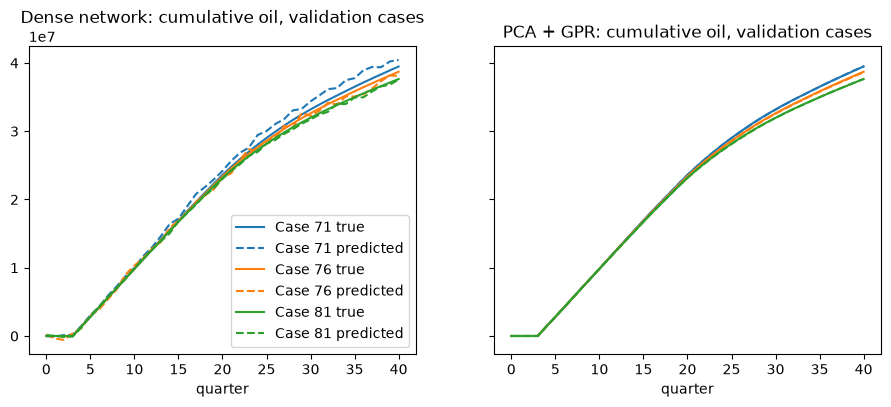

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, p) in zip(axes, [('Dense network', pred), ('PCA + GPR', pred_gpr)]):
    for i, c in enumerate([0, 5, 10]):
        ax.plot(true[c, :41], color=f'C{i}', label=f'Case {71+c} true')
        ax.plot(p[c, :41], '--', color=f'C{i}', label=f'Case {71+c} predicted')
    ax.set_title(f'{name}: cumulative oil, validation cases')
    ax.set_xlabel('quarter')
axes[0].legend()
plt.savefig(f'{OUT_DIR}/model_comparison_oil.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame(results).T.round(2).to_csv(f'{OUT_DIR}/model_comparison_validation.csv')

## Test cases (run once, after choosing the model)

In [13]:
BEST = 'PCA + GPR'

pred_test = predict_gpr(X[test_idx])
test_errors = errors(pred_test, Y[test_idx])
print('Test errors for', BEST)
print(pd.Series(test_errors).round(2))

Test errors for PCA + GPR
oil whole-curve %      0.09
oil at 2008 %          0.10
gas whole-curve %      0.09
gas at 2008 %          0.11
water whole-curve %    0.42
water at 2008 %        0.33
dtype: float64


## Step f: history matching

In [14]:
Y_obs = np.concatenate([oil['Observed'].values, gas['Observed'].values, water['Observed'].values])
obs_final = np.concatenate([np.full(41, Y_obs[k*41 + 40]) for k in range(3)])

rng = np.random.default_rng(42)
lo, hi = X.min(axis=0), X.max(axis=0)
candidates = rng.uniform(lo, hi, size=(100000, 4))
cand_pred = predict_gpr(candidates)

mismatch = np.mean(np.abs(cand_pred - Y_obs) / obs_final, axis=1) * 100
order = np.argsort(mismatch)

print('best 5 mismatches (%):', mismatch[order[:5]].round(3))
print(pd.DataFrame(candidates[order[:5]], columns=SETTING_COLS).round(3))

case90_mismatch = np.mean(np.abs(Y[89] - Y_obs) / obs_final) * 100
print('Case 90 itself: mismatch', round(case90_mismatch, 3), '%, settings', X[89].round(3))

best 5 mismatches (%): [0.214 0.215 0.215 0.216 0.216]
   Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  \
0                   0.061                1.374                    9.682   
1                   0.101                1.373                    9.435   
2                   0.064                1.370                    9.749   
3                   0.096                1.369                    9.475   
4                   0.091                1.379                    9.632   

   Aquifer Pore Volume  
0              196.524  
1              196.051  
2              188.475  
3              193.090  
4              197.132  
Case 90 itself: mismatch 0.484 %, settings [6.1000e-02 1.3150e+00 6.0060e+00 1.3518e+02]


## Choosing the 10 cases for the template

   Case  Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  Aquifer Pore Volume  mismatch %
 Case 1                   0.061                1.374                    9.682              196.524       0.214
 Case 2                   0.101                1.373                    9.435              196.051       0.215
 Case 3                   0.091                1.379                    9.632              197.132       0.216
 Case 4                   0.144                1.371                    9.553              190.969       0.216
 Case 5                   0.080                1.371                    9.777              194.653       0.218
 Case 6                   0.101                1.315                    9.770               58.266       0.218
 Case 7                   0.139                1.313                    9.602               55.663       0.218
 Case 8                   0.072                1.368                    9.238              191.246       0.218
 

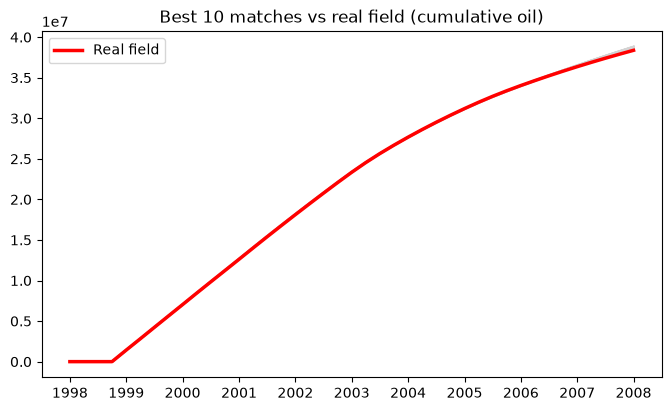

In [15]:
span = hi - lo
chosen = []
for i in order:
    z = (candidates[i] - lo) / span
    if all(np.linalg.norm(z - (candidates[j] - lo) / span) >= 0.10 for j in chosen):
        chosen.append(i)
    if len(chosen) == 10:
        break

best_settings = candidates[chosen]
best_curves = cand_pred[chosen]
best_table = pd.DataFrame(best_settings, columns=SETTING_COLS)
best_table.insert(0, 'Case', [f'Case {k+1}' for k in range(10)])
best_table['mismatch %'] = mismatch[chosen]
print(best_table.round(3).to_string(index=False))
best_table.to_csv(f'{OUT_DIR}/best10_settings.csv', index=False)

plt.figure(figsize=(8, 4.5))
for c in best_curves:
    plt.plot(oil.index, c[:41], color='lightgrey')
plt.plot(oil.index, Y_obs[:41], color='red', linewidth=2.5, label='Real field')
plt.title('Best 10 matches vs real field (cumulative oil)')
plt.legend()
plt.show()

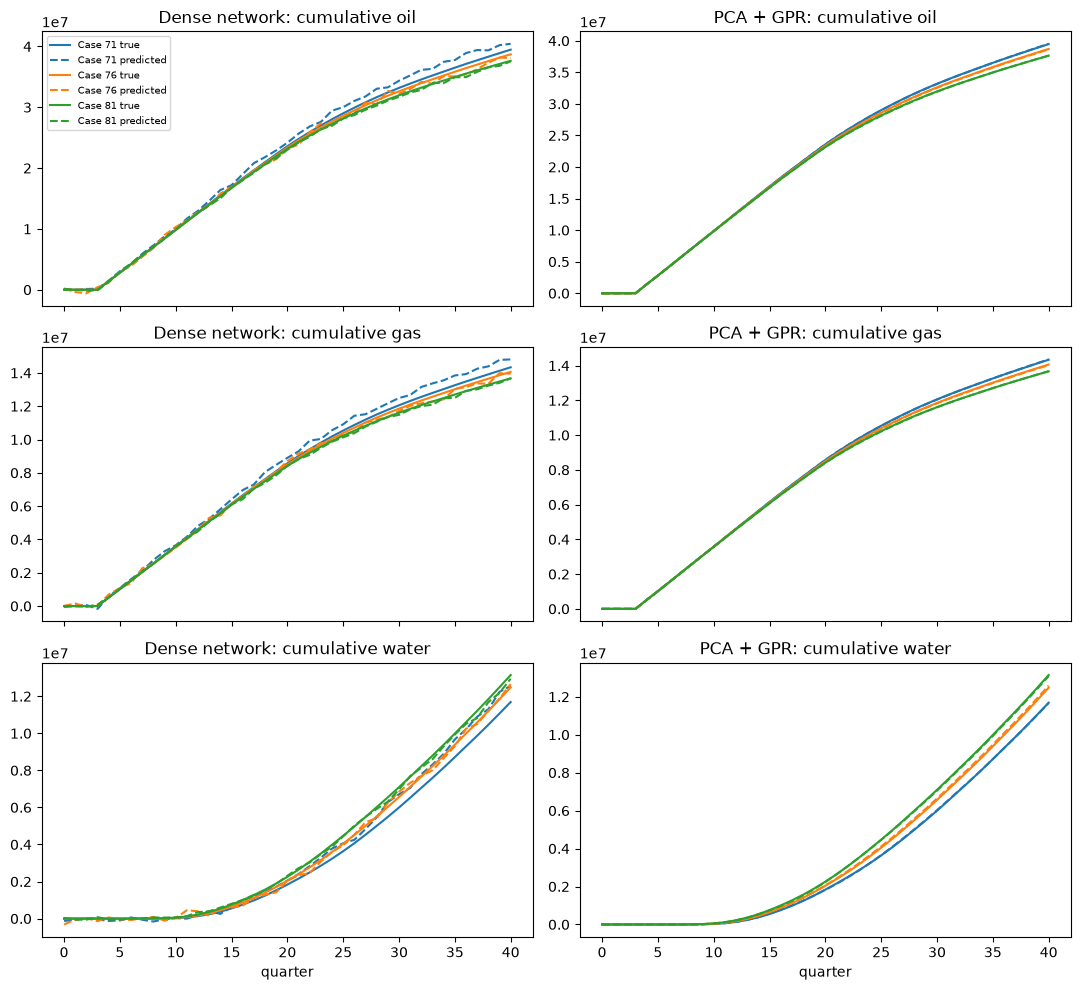

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
names = ['oil', 'gas', 'water']
for r, fluid in enumerate(names):
    for col, (title, p) in enumerate([('Dense network', pred), ('PCA + GPR', pred_gpr)]):
        ax = axes[r, col]
        for i, c in enumerate([0, 5, 10]):
            ax.plot(true[c, r*41:(r+1)*41], color=f'C{i}', label=f'Case {71+c} true')
            ax.plot(p[c, r*41:(r+1)*41], '--', color=f'C{i}', label=f'Case {71+c} predicted')
        ax.set_title(f'{title}: cumulative {fluid}')
axes[0, 0].legend(fontsize=7)
axes[2, 0].set_xlabel('quarter'); axes[2, 1].set_xlabel('quarter')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/model_comparison_all_fluids.png', dpi=200, bbox_inches='tight')
plt.show()

In [17]:
case_mismatch = np.mean(np.abs(Y - Y_obs) / obs_final, axis=1) * 100
top = np.argsort(case_mismatch)[:10]
print(pd.DataFrame({'case': top + 1, 'mismatch %': case_mismatch[top].round(3)}).to_string(index=False))
print('our 10 new combinations:', mismatch[chosen].min().round(3), 'to', mismatch[chosen].max().round(3))

 case  mismatch %
   11       0.226
   76       0.227
   40       0.228
    6       0.233
   50       0.238
   97       0.255
   20       0.256
   73       0.269
   26       0.319
    4       0.374
our 10 new combinations: 0.214 to 0.22


In [18]:
best_given = pd.DataFrame(X[top], columns=SETTING_COLS)
best_given.insert(0, 'Given case', top + 1)
best_given['mismatch %'] = case_mismatch[top].round(3)
print(best_given.round(3).to_string(index=False))
best_given.to_csv(f'{OUT_DIR}/best10_given_cases.csv', index=False)

 Given case  Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  Aquifer Pore Volume  mismatch %
         11                   0.125                1.354                    7.338              188.082       0.226
         76                   0.108                1.383                    1.640              182.202       0.227
         40                   0.144                1.354                    4.961              132.522       0.228
          6                   0.058                1.358                    2.468              119.765       0.233
         50                   0.100                1.357                    7.459              170.739       0.238
         97                   0.052                1.346                    5.409              153.886       0.255
         20                   0.062                1.361                    5.078              123.383       0.256
         73                   0.083                1.354                    1.47

## Step g: forecast to 1 Jan 2028 (liquid, WOR, GOR method)

In [19]:
def forecast_case(oil_c, gas_c, water_c, n_ahead, n_fit=12):
    """Takes cumulative oil/gas/water up to some date, returns cumulative curves for n_ahead more quarters."""
    oil_q, gas_q, water_q = np.diff(oil_c), np.diff(gas_c), np.diff(water_c)   # volume per quarter
    o = np.clip(oil_q[-n_fit:], 1e-9, None)
    liquid = o + np.clip(water_q[-n_fit:], 0, None)       # total liquid = oil + water
    wor = np.clip(water_q[-n_fit:], 1e-9, None) / o        # water-to-oil ratio
    gor = np.clip(gas_q[-n_fit:], 1e-9, None) / o          # gas-to-oil ratio

    t = np.arange(n_fit)
    t_new = n_fit - 1 + np.arange(1, n_ahead + 1)
    def extend(series):                                    # straight line through the log of the series
        slope, intercept = np.polyfit(t, np.log(series), 1)
        return np.exp(intercept + slope * t_new)

    liquid_f, wor_f, gor_f = extend(liquid), extend(wor), extend(gor)
    oil_f = liquid_f / (1 + wor_f)
    water_f = liquid_f - oil_f
    gas_f = gor_f * oil_f
    return (oil_c[-1] + np.cumsum(oil_f),
            gas_c[-1] + np.cumsum(gas_f),
            water_c[-1] + np.cumsum(water_f))

# check: hide the last 2 years (2006-2008), forecast them from the earlier years, compare
CUT = 32            # history stops at quarter 32 (Jan 2006); forecast the last 8 quarters
rows = []
for n_fit in [8, 12, 16]:
    errs = {'oil': [], 'gas': [], 'water': []}
    for c in range(100):
        o, g, w = Y[c, :41], Y[c, 41:82], Y[c, 82:]
        fo, fg, fw = forecast_case(o[:CUT+1], g[:CUT+1], w[:CUT+1], 40 - CUT, n_fit)
        for name, f, true in [('oil', fo, o), ('gas', fg, g), ('water', fw, w)]:
            errs[name].append(abs(f[-1] - true[-1]) / true[-1] * 100)
    rows.append({'quarters used for trend': n_fit,
                 **{f'{k} median error %': round(float(np.median(v)), 2) for k, v in errs.items()}})
print(pd.DataFrame(rows).to_string(index=False))

 quarters used for trend  oil median error %  gas median error %  water median error %
                       8                1.51                1.51                  0.74
                      12                1.53                1.52                  1.99
                      16                2.47                2.48                  2.38


Total oil by 2028 (million STB), window 8 vs window 12
Case 11: 56.8 vs 52.3  (difference 8.8%)
Case 76: 56.4 vs 52.0  (difference 8.5%)
Case 40: 56.8 vs 52.2  (difference 8.8%)
Case 6: 55.6 vs 51.4  (difference 8.2%)
Case 50: 57.0 vs 52.4  (difference 8.9%)
Case 97: 56.6 vs 52.0  (difference 8.8%)
Case 20: 57.1 vs 52.5  (difference 8.8%)
Case 73: 55.8 vs 51.2  (difference 9.1%)
Case 26: 56.1 vs 51.3  (difference 9.4%)
Case 4: 57.5 vs 52.7  (difference 9.1%)


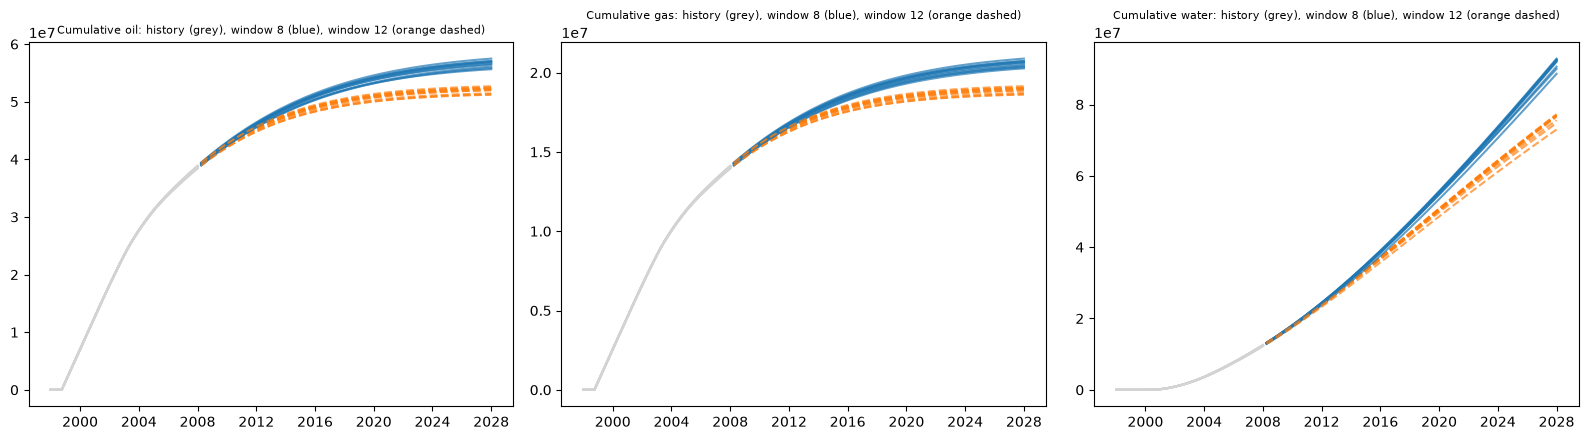

In [20]:
N_AHEAD = 80
fdates = pd.date_range('2008-04-01', '2028-01-01', freq='QS')
assert len(fdates) == N_AHEAD

fc = {}
for n_fit in [8, 12]:
    fc[n_fit] = np.array([np.concatenate(forecast_case(Y[c, :41], Y[c, 41:82], Y[c, 82:], N_AHEAD, n_fit))
                          for c in top])        # 10 cases x (80 oil + 80 gas + 80 water)

print('Total oil by 2028 (million STB), window 8 vs window 12')
for i, c in enumerate(top):
    a, b = fc[8][i, 79] / 1e6, fc[12][i, 79] / 1e6
    print(f'Case {c+1}: {a:.1f} vs {b:.1f}  (difference {abs(a-b)/b*100:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for k, fluid in enumerate(['oil', 'gas', 'water']):
    for i, c in enumerate(top):
        axes[k].plot(oil.index, Y[c, k*41:(k+1)*41], color='lightgrey')
        axes[k].plot(fdates, fc[8][i, k*80:(k+1)*80], color='tab:blue', alpha=0.7)
        axes[k].plot(fdates, fc[12][i, k*80:(k+1)*80], color='tab:orange', alpha=0.7, linestyle='--')
    axes[k].set_title(f'Cumulative {fluid}: history (grey), window 8 (blue), window 12 (orange dashed)', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/forecast_charts.png', dpi=200, bbox_inches='tight')
plt.show()

## Fill the updated forecast template

In [21]:
from openpyxl import load_workbook
import glob

BASE_WINDOW = 12
template_path = sorted(glob.glob(f'{DATA_DIR}/09*.xlsx'))[0]
print('using template:', template_path)

wb = load_workbook(template_path)
for i, c in enumerate(top):                       # sheet "Case 1" gets the closest provided case, and so on
    ws = wb[f'Case {i+1}']
    assert ws.max_row - 1 == N_AHEAD, f'{ws.title} has {ws.max_row - 1} rows, expected {N_AHEAD}'
    headers = {str(cell.value).lower(): cell.column for cell in ws[1] if cell.value}
    for k, fluid in enumerate(['oil', 'gas', 'water']):
        col = next(v for h, v in headers.items() if h.startswith(fluid))
        for r in range(N_AHEAD):
            ws.cell(row=r + 2, column=col, value=float(fc[BASE_WINDOW][i, k*80 + r]))   # dates stay untouched
wb.save(f'{OUT_DIR}/forecast_filled_template.xlsx')

pd.DataFrame({'template sheet': [f'Case {i+1}' for i in range(10)], 'provided case': top + 1}
             ).to_csv(f'{OUT_DIR}/template_case_mapping.csv', index=False)

# check
filled = pd.read_excel(f'{OUT_DIR}/forecast_filled_template.xlsx', sheet_name=None)
for sheet, df in filled.items():
    vals = df.iloc[:, 1:4]
    assert len(df) == 80 and not vals.isna().any().any(), f'{sheet}: wrong size or blank cells'
    assert (vals.diff().dropna() >= 0).all().all(), f'{sheet}: a cumulative total goes down'
print('all', len(filled), 'sheets passed: 80 rows, no blanks, totals never decrease')
print(filled['Case 1'].iloc[[0, -1]].to_string())

using template: data/09 Template Deliverable.xlsx
all 10 sheets passed: 80 rows, no blanks, totals never decrease
                   Date  Gas production cumulative [MSCF]  Oil production cumulative [STB]  Water production cumulative [STB]
0            04/01/2008                      1.425643e+07                     3.924148e+07                       1.312445e+07
79  2028-01-01 00:00:00                      1.898305e+07                     5.225177e+07                       7.701694e+07


quarter ending   period  oil volume [STB]  oil rate [STB/d]  gas rate [MSCF/d]  water rate [STB/d]
    2007-07-01  history          575048.0            6319.0             2296.0              6746.0
    2007-10-01  history          568836.0            6183.0             2246.0              6866.0
    2008-01-01  history          556380.0            6048.0             2197.0              6982.0
    2008-04-01 forecast          525563.0            5775.0             2098.0              7117.0
    2008-07-01 forecast          509908.0            5603.0             2036.0              7227.0
    2008-10-01 forecast          494466.0            5375.0             1953.0              7255.0


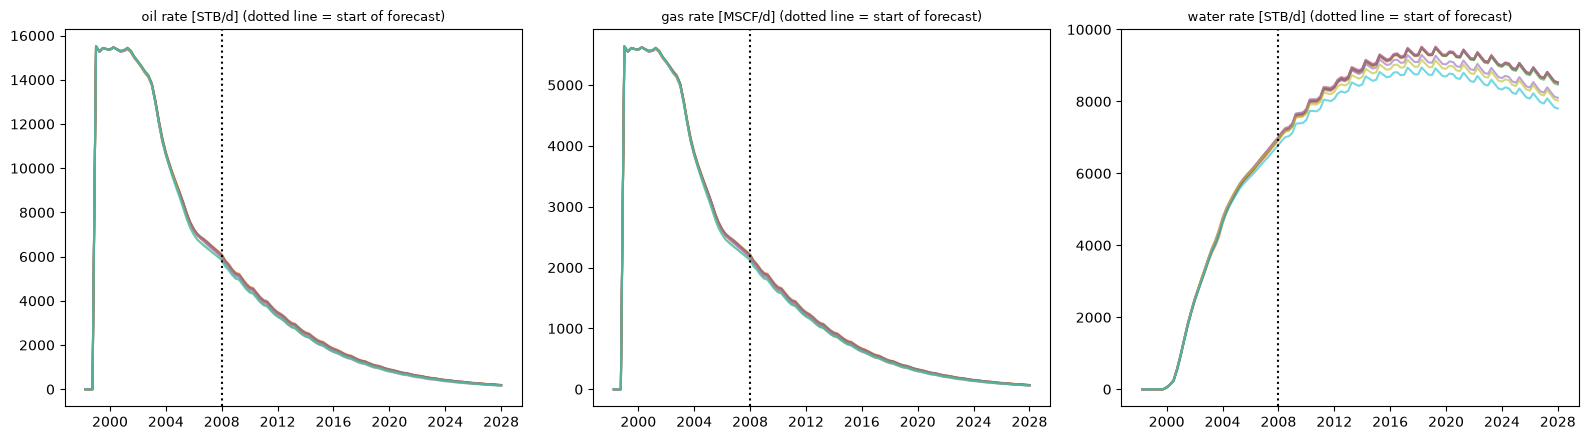

In [22]:
BASE_WINDOW = 12
all_dates = oil.index.append(fdates)                       # 41 history dates + 80 forecast dates
days = np.diff(all_dates.values).astype('timedelta64[D]').astype(int)   # days in each quarter

rows = []
for i, c in enumerate(top):
    vols = {}
    for k, fluid in enumerate(['oil', 'gas', 'water']):
        full = np.concatenate([Y[c, k*41:(k+1)*41], fc[BASE_WINDOW][i, k*80:(k+1)*80]])   # cumulative, history then forecast
        vols[fluid] = np.diff(full)                         # volume produced in each quarter
    for q in range(len(days)):
        rows.append({'template sheet': f'Case {i+1}', 'provided case': c + 1,
                     'quarter ending': all_dates[q + 1].date(),
                     'period': 'history' if q < 40 else 'forecast',
                     'oil volume [STB]': vols['oil'][q], 'gas volume [MSCF]': vols['gas'][q],
                     'water volume [STB]': vols['water'][q],
                     'oil rate [STB/d]': vols['oil'][q] / days[q], 'gas rate [MSCF/d]': vols['gas'][q] / days[q],
                     'water rate [STB/d]': vols['water'][q] / days[q]})
rates = pd.DataFrame(rows)
rates.to_csv(f'{OUT_DIR}/quarterly_volumes_and_rates.csv', index=False)

c1 = rates[rates['template sheet'] == 'Case 1']
print(c1.iloc[37:43][['quarter ending', 'period', 'oil volume [STB]', 'oil rate [STB/d]', 'gas rate [MSCF/d]', 'water rate [STB/d]']].round(0).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['oil rate [STB/d]', 'gas rate [MSCF/d]', 'water rate [STB/d]']):
    for sheet, g in rates.groupby('template sheet'):
        ax.plot(pd.to_datetime(g['quarter ending']), g[col], alpha=0.6)
    ax.axvline(pd.Timestamp('2008-01-01'), color='k', linestyle=':')
    ax.set_title(col + ' (dotted line = start of forecast)', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/forecast_rates.png', dpi=200, bbox_inches='tight')
plt.show()

## Revenue scenarios

In [23]:
PRICES = {'low':  (94.302 * 0.8, 3.2675 * 0.8),     # (oil USD per STB, gas USD per MSCF)
          'base': (94.302,       3.2675),
          'high': (94.302 * 1.2, 3.2675 * 1.2)}

fcst = rates[rates['period'] == 'forecast']             # 2008-2028 only
vol = fcst.groupby('template sheet')[['oil volume [STB]', 'gas volume [MSCF]']].sum()
vol = vol.reindex([f'Case {i+1}' for i in range(10)])

revenue = pd.DataFrame({'provided case': top + 1}, index=vol.index)
revenue['oil produced [million STB]'] = vol['oil volume [STB]'] / 1e6
revenue['gas produced [million MSCF]'] = vol['gas volume [MSCF]'] / 1e6
for name, (p_oil, p_gas) in PRICES.items():
    revenue[f'revenue {name} [USD million]'] = (vol['oil volume [STB]'] * p_oil + vol['gas volume [MSCF]'] * p_gas) / 1e6

print(revenue.round(1).to_string())
print('oil share of base revenue: %.1f%%' % (
    (vol['oil volume [STB]'] * PRICES['base'][0]).sum() /
    (vol['oil volume [STB]'] * PRICES['base'][0] + vol['gas volume [MSCF]'] * PRICES['base'][1]).sum() * 100))
revenue.round(2).to_csv(f'{OUT_DIR}/revenue_scenarios.csv')

                provided case  oil produced [million STB]  gas produced [million MSCF]  revenue low [USD million]  revenue base [USD million]  revenue high [USD million]
template sheet                                                                                                                                                           
Case 1                     11                        13.5                          4.9                     1034.0                      1292.5                      1551.0
Case 2                     76                        13.3                          4.8                     1015.5                      1269.4                      1523.3
Case 3                     40                        13.5                          4.9                     1031.0                      1288.7                      1546.5
Case 4                      6                        12.8                          4.7                      979.6                      1224.5         

## Assumptions file

In [24]:
OIL_BENCHMARK = "WTI crude"
GAS_BENCHMARK = "natural gas futures, quoted in USD/MMBtu"

lo, hi = revenue['revenue base [USD million]'].min(), revenue['revenue base [USD million]'].max()

text = f"""# Assumptions - DWC26 forecast (1 Jan 2008 to 1 Jan 2028)

## Model and case selection
- Proxy model: PCA (4 components) + Gaussian Process Regression, trained on cases 1-70,
  validated on 71-85, tested on 86-100. A Keras dense network was the benchmark (about 18x less accurate).
- History matching: 100,000 random parameter combinations scored against observed production 1998-2008.
- The 10 submitted cases are the provided cases closest to the observed history: {', '.join(str(c) for c in top + 1)}.
- No CNN: the static maps of all cases are scaled copies of one template, so they add no new information.

## Forecast method
- Operating conditions stay unchanged after 2008 (organizer FAQ).
- Total liquid, water-to-oil ratio (WOR) and gas-to-oil ratio (GOR) are extrapolated with log-linear fits
  over the last 12 quarters (base case). A 8-quarter window is the upside case.
- Oil = liquid / (1 + WOR). Gas = oil x GOR. Water = liquid - oil.
- Window length was chosen by hiding the last 2 years and comparing the forecast to what actually happened.

## Prices (revenue scenarios)
- Oil: USD 94.302 per STB, {OIL_BENCHMARK}, 15 Oct 2026, 9am MYT.
- Gas: USD 3.2675 per MSCF, {GAS_BENCHMARK}, 15 Oct 2026, 9am MYT.
  MMBtu is treated as MSCF (1 MSCF is about 1.037 MMBtu).
- Low / base / high = 80% / 100% / 120% of today's price, held constant for 20 years.

## Revenue
- Revenue = oil volume x oil price + gas volume x gas price.
- Undiscounted, no costs, taxes or royalties, so this is revenue, not profit.
- Base revenue across the 10 cases: USD {lo:.0f} million to {hi:.0f} million.
- Oil is about 98.8% of base revenue.

## Limits
- History fixes porosity well but not permeability, so the 10 cases give near-identical forecasts.
- Rates are extrapolated trends, not a new reservoir simulation.
"""
with open(f'{OUT_DIR}/assumptions.md', 'w') as f:
    f.write(text)
print(text)

# Assumptions - DWC26 forecast (1 Jan 2008 to 1 Jan 2028)

## Model and case selection
- Proxy model: PCA (4 components) + Gaussian Process Regression, trained on cases 1-70,
  validated on 71-85, tested on 86-100. A Keras dense network was the benchmark (about 18x less accurate).
- History matching: 100,000 random parameter combinations scored against observed production 1998-2008.
- The 10 submitted cases are the provided cases closest to the observed history: 11, 76, 40, 6, 50, 97, 20, 73, 26, 4.
- No CNN: the static maps of all cases are scaled copies of one template, so they add no new information.

## Forecast method
- Operating conditions stay unchanged after 2008 (organizer FAQ).
- Total liquid, water-to-oil ratio (WOR) and gas-to-oil ratio (GOR) are extrapolated with log-linear fits
  over the last 12 quarters (base case). A 8-quarter window is the upside case.
- Oil = liquid / (1 + WOR). Gas = oil x GOR. Water = liquid - oil.
- Window length was chosen by hiding the last 2 ye